# 02 文本预处理和 TF-IDF 特征实验

负责人：成员 3。输入：成员 2 生成的 `data/processed/train.csv`、`test.csv` 和 `split_manifest.csv`。

输出：训练集内五折 unigram/bigram 对比、稀疏特征、拟合后的向量化器、特征总结和英文图表。测试集只做 transform，不计算测试指标或选择参数。

先按根目录 README 安装项目，运行成员 2 的 EDA 命令。所有可复用逻辑位于 `src/restaurant_sentiment/preprocessing.py`。

In [1]:
from pathlib import Path
import sys

# Make the notebook work from a fresh clone before editable installation.
notebook_dir = Path.cwd()
if (notebook_dir / 'pyproject.toml').is_file():
    project_root = notebook_dir
elif (notebook_dir.parent / 'pyproject.toml').is_file():
    project_root = notebook_dir.parent
else:
    raise FileNotFoundError('请从项目根目录或 notebooks 目录运行')
sys.path.insert(0, str(project_root / 'src'))
import json
import pandas as pd
from IPython.display import Image, display
from restaurant_sentiment.preprocessing import load_fixed_partitions, run_preprocessing
from restaurant_sentiment.features import build_tfidf

root = project_root
train, test = load_fixed_partitions(root / 'data' / 'processed')
pd.DataFrame({'Partition': ['Train', 'Test'], 'Reviews': [len(train), len(test)]})

,Partition,Reviews
0,Train,796
1,Test,200


## 预处理决定
沿用成员 2 的清洗与固定划分，不重新分割数据。使用小写和 Unicode 去音调，默认词级分词保留至少两个字符的词。保留 `not`、`no`、`never` 等否定词，不移除停用词，不做词干化或词形还原。

默认分词会拆开英文缩写、丢弃单字符片段，因此不能完整保留 `isn't` 等缩写的否定含义；标点强度和长距离语序也不在特征中。bigram 是对分词后相邻词的补充，而不是完整句法模型。

采用 sublinear TF、平滑 IDF 和 L2 归一化。`min_df=1`，无词汇数上限。完整 pipeline 在每个训练折内重新拟合，不能先在全部训练集拟合 TF-IDF 再交叉验证。

In [2]:
analyzer = build_tfidf(ngram_range=(1, 2)).build_analyzer()
analyzer("Café food is not good; I won't return.")

['cafe',
 'food',
 'is',
 'not',
 'good',
 'won',
 'return',
 'cafe food',
 'food is',
 'is not',
 'not good',
 'good won',
 'won return']

## 训练集内对比
两种特征使用相同的五折分层划分，`shuffle=True`、`random_state=8017`。固定 Linear SVM `C=1` 作为特征选择探针；Multinomial NB `alpha=1` 用于敏感性对比，不代替成员 4 的调参和成员 5 的正式评估。

选择规则事先固定为 SVM 的五折平均正类 F1 最高，同分优先 unigram。Accuracy、Precision、Recall 和 ROC-AUC 同时保留供比较；标准差按样本标准差计算，不是置信区间。

In [3]:
metadata = run_preprocessing(root)
comparison = pd.read_csv(root / 'results/tables/tfidf_cv_comparison.csv')
comparison.round(4)

,variant,model,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,roc_auc_mean,roc_auc_std
0,unigram,svm,0.8015,0.0296,0.8054,0.0427,0.7996,0.0390,0.8016,0.0282,0.8953,0.0273
1,unigram,nb,0.7965,0.0445,0.8008,0.0571,0.7972,0.0784,0.7962,0.0484,0.8802,0.0340
2,unigram_bigram,svm,0.8041,0.0330,0.8177,0.0291,0.7846,0.0616,0.7998,0.0388,0.8972,0.0232
3,unigram_bigram,nb,0.7852,0.0365,0.7893,0.0420,0.7821,0.0598,0.7845,0.0394,0.8809,0.0350


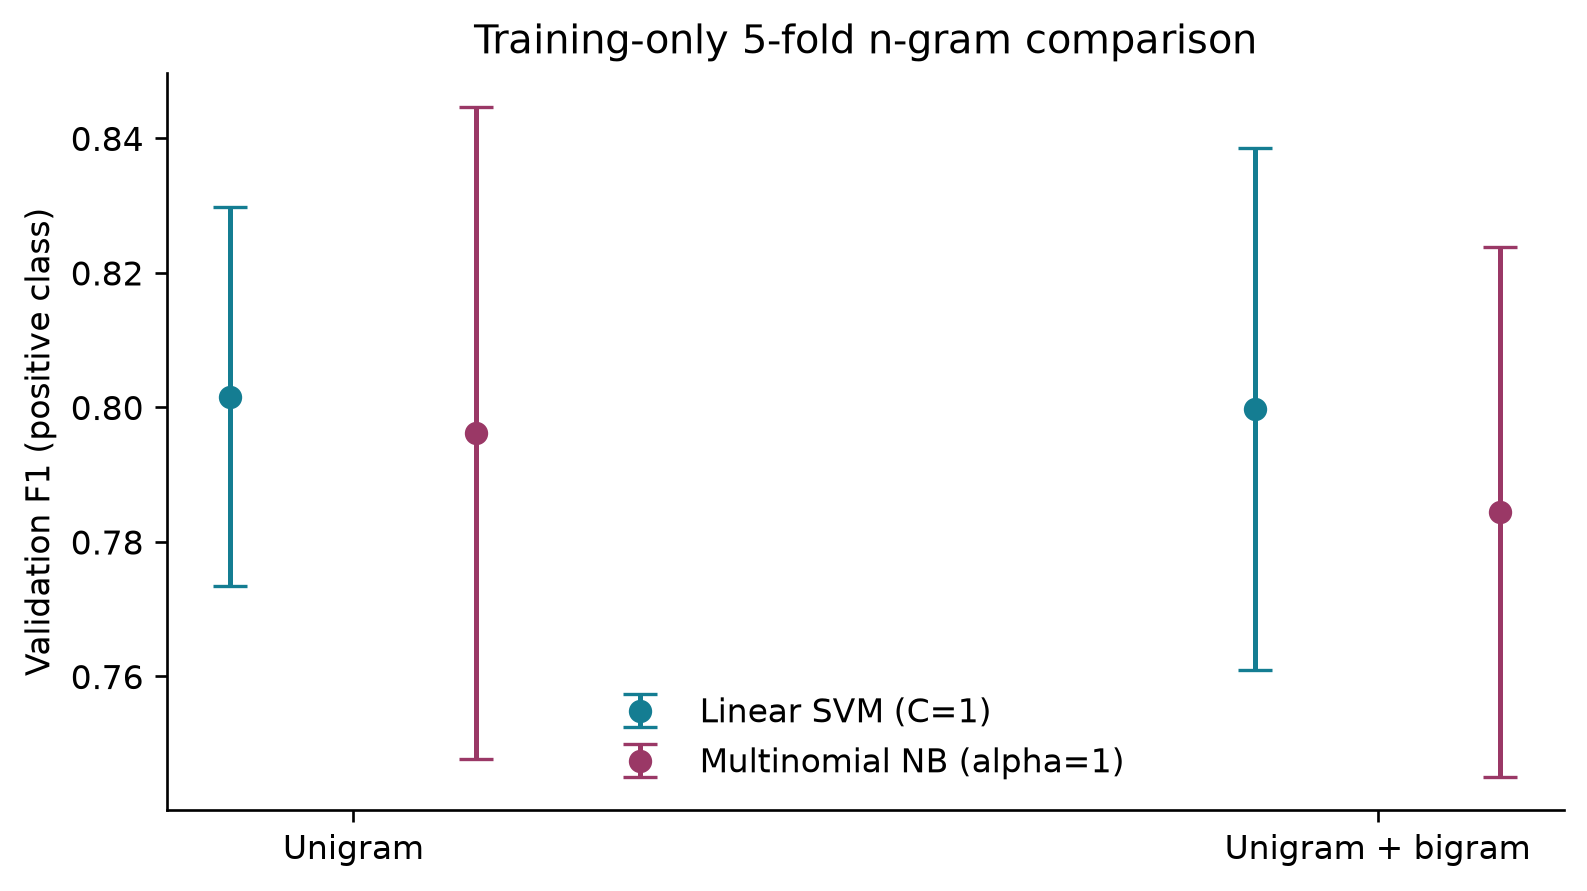

In [4]:
display(Image(filename=str(root / 'results/figures/tfidf_ngram_cv_f1.png')))

In [5]:
pd.read_csv(root / 'results/tables/tfidf_feature_summary.csv')

,variant,partition,rows,features,nonzero,density,zero_rows
0,unigram,train,796,1781,7836,0.005527,0
1,unigram,test,200,1781,1653,0.004641,0
2,unigram_bigram,train,796,7345,15269,0.002612,0
3,unigram_bigram,test,200,7345,2342,0.001594,0


In [6]:
pd.read_csv(root / 'results/tables/tfidf_top_training_terms.csv').groupby('variant', sort=False).head(10)

,variant,term,train_document_frequency,mean_train_tfidf
0,unigram,the,361,0.060248
1,unigram,was,216,0.048465
2,unigram,and,258,0.045981
3,unigram,to,146,0.030979
4,unigram,is,114,0.030871
5,unigram,it,110,0.028849
6,unigram,food,92,0.028579
7,unigram,this,107,0.028278
8,unigram,good,77,0.027464
9,unigram,not,95,0.026671


## 交接给成员 4 和 5
默认共用 unigram；其训练词汇表有 1781 项，unigram + bigram 有 7345 项。SVM 的平均 F1 分别为 0.8016 和 0.7998，差距小于折间波动，不能宣称显著优势。

正式模型继续使用同一固定划分。交叉验证时从 `build_pipeline` 创建完整 pipeline；最终拟合可以读取导出的稀疏特征，但不能将已在全部训练集拟合的特征用于内部交叉验证。

矩阵行顺序与 `train_rows.csv`、`test_rows.csv` 对齐。词汇表、IDF 和非零值均仅在训练文本拟合。`models/tfidf/feature_config.json` 保存推荐设置、依赖版本和输入文件 SHA-256；joblib 只加载可信文件。完整中文交接说明见 `docs/member3_tfidf.md`；英文小节见 `report/text_features.tex`。

In [7]:
assert metadata['test_metrics_computed'] is False
print(json.dumps(metadata, indent=2))

{
  "random_state": 8017,
  "cv_folds": 5,
  "cv_std_ddof": 1,
  "selected_variant": "unigram",
  "selection_rule": "Highest mean training-fold positive-class F1 with fixed LinearSVC(C=1); ties prefer unigram.",
  "test_metrics_computed": false,
  "vectorizer_parameters": {
    "analyzer": "word",
    "binary": false,
    "decode_error": "strict",
    "encoding": "utf-8",
    "input": "content",
    "lowercase": true,
    "max_df": 1.0,
    "max_features": null,
    "min_df": 1,
    "ngram_range": [
      1,
      1
    ],
    "norm": "l2",
    "preprocessor": null,
    "smooth_idf": true,
    "stop_words": null,
    "strip_accents": "unicode",
    "sublinear_tf": true,
    "token_pattern": "(?u)\\b\\w\\w+\\b",
    "tokenizer": null,
    "use_idf": true,
    "vocabulary": null
  },
  "probe_parameters": {
    "svm": {
      "C": 1.0
    },
    "nb": {
      "alpha": 1.0
    }
  },
  "input_sha256": {
    "train.csv": "cb874f345b78bd41ed234354aafd84583fac5d96e39c0d2515e5b3adf2514e6c",
 